# Retail Customer Retention Intelligence
## Phase 3 — Customer Segmentation and Churn Modeling

This phase converts historical purchasing behavior into customer-level features for segmentation and churn prediction.

The workflow is:

1. construct leakage-safe historical customer snapshots;
2. create RFM features;
3. compare rule-based RFM segmentation with K-Means clustering;
4. generate 90-day churn labels;
5. train a Logistic Regression baseline;
6. compare it with a gradient-boosted tree model;
7. evaluate models using time-based validation, PR-AUC, and recall at a limited customer-contact budget.

All predictive features are calculated using information available before each historical cutoff date.

### 3.1 Environment Setup

In [20]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from dotenv import load_dotenv

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    classification_report,
    confusion_matrix,
)


# Locate the project root and load environment variables.
PROJECT_ROOT = Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")


# PostgreSQL connection.
DATABASE_URL = (
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:"
    f"{os.getenv('DB_PASSWORD')}@"
    f"{os.getenv('DB_HOST')}:"
    f"{os.getenv('DB_PORT')}/"
    f"{os.getenv('DB_NAME')}"
)

engine = create_engine(DATABASE_URL)

print("Phase 3 environment ready.")

Phase 3 environment ready.


### 3.2 Build Leakage-Safe Historical Customer Snapshots

For each historical cutoff date, customer features are calculated using only purchases from the preceding 180-day observation window.

Churn is then determined using the following 90-day label window:

- `churn = 1` → no qualifying merchandise purchase during the next 90 days;
- `churn = 0` → at least one qualifying merchandise purchase during the next 90 days.

Keeping the feature and label windows separate prevents future purchasing information from leaking into model inputs.

#### 3.2.1 First Training Snapshot — 2010-09-01

In [21]:
# Define the first historical cutoff and its time windows.
cutoff_date = pd.Timestamp("2010-09-01")
observation_start = cutoff_date - pd.Timedelta(days=180)
label_end = cutoff_date + pd.Timedelta(days=90)

print("Observation window:")
print(observation_start.date(), "to", cutoff_date.date())

print("\nLabel window:")
print(cutoff_date.date(), "to", label_end.date())

Observation window:
2010-03-05 to 2010-09-01

Label window:
2010-09-01 to 2010-11-30


#### 3.2.2 Generate the First Customer Snapshot

Eligible customers are those with at least one qualifying merchandise purchase during the 180-day observation window.

For each eligible customer, the snapshot calculates historical purchasing features using only information available before the cutoff date. The following 90-day period is used only to determine the churn label.

In [22]:
snapshot_query = """
WITH observation AS (
    SELECT
        customer_id,
        MAX(invoice_date) AS last_purchase_date,
        COUNT(DISTINCT invoice) AS frequency,
        SUM(line_revenue) AS monetary_value,
        SUM(quantity) AS total_units,
        SUM(line_revenue) / COUNT(DISTINCT invoice) AS avg_order_value
    FROM retail_transactions
    WHERE invoice_date >= :observation_start
      AND invoice_date < :cutoff_date
    GROUP BY customer_id
),

future_purchases AS (
    SELECT DISTINCT customer_id
    FROM retail_transactions
    WHERE invoice_date >= :cutoff_date
      AND invoice_date < :label_end
)

SELECT
    o.customer_id,

    CAST(:cutoff_date AS timestamp) AS cutoff_date,

    -- Days since the customer's last purchase before the cutoff.
    CAST(:cutoff_date AS date)
        - CAST(o.last_purchase_date AS date) AS recency_days,

    -- Historical purchasing features.
    o.frequency,
    ROUND(o.monetary_value, 2) AS monetary_value,
    o.total_units,
    ROUND(o.avg_order_value, 2) AS avg_order_value,

    -- Future behavior is used only to create the target.
    CASE
        WHEN f.customer_id IS NULL THEN 1
        ELSE 0
    END AS churn

FROM observation o

LEFT JOIN future_purchases f
    ON o.customer_id = f.customer_id

ORDER BY o.customer_id;
"""

params = {
    "observation_start": observation_start,
    "cutoff_date": cutoff_date,
    "label_end": label_end,
}

with engine.connect() as connection:
    snapshot_2010_09 = pd.read_sql(
        text(snapshot_query),
        connection,
        params=params
    )

print("Snapshot shape:", snapshot_2010_09.shape)
snapshot_2010_09.head()

Snapshot shape: (2822, 8)


,customer_id,cutoff_date,recency_days,frequency,monetary_value,total_units,avg_order_value,churn
0,12346,2010-09-01,65,1,142.31,19,142.31,1
1,12349,2010-09-01,125,1,1068.52,473,1068.52,0
2,12355,2010-09-01,103,1,488.21,303,488.21,1
3,12358,2010-09-01,86,1,268.10,281,268.10,0
4,12359,2010-09-01,71,3,1173.14,268,391.05,0


#### 3.2.3 Validate the First Snapshot

The first historical snapshot is checked for duplicate customers, missing feature values, and churn-class distribution before the same process is applied to the remaining cutoff dates.

In [23]:
print("Customers:", len(snapshot_2010_09))
print(
    "Duplicate customer rows:",
    snapshot_2010_09["customer_id"].duplicated().sum()
)
print(
    "Missing values:",
    snapshot_2010_09.isna().sum().sum()
)

print("\nChurn counts:")
print(
    snapshot_2010_09["churn"]
    .value_counts()
    .sort_index()
)

print(
    "\nChurn rate:",
    f"{snapshot_2010_09['churn'].mean():.2%}"
)

Customers: 2822
Duplicate customer rows: 0
Missing values: 0

Churn counts:
churn
0    1750
1    1072
Name: count, dtype: int64

Churn rate: 37.99%


#### First Snapshot Validation — Interpretation

The 2010-09-01 snapshot contains 2,822 eligible customers with no duplicate customer records or missing values.

Of these customers:

- 1,750 (62.01%) made another purchase during the following 90 days.
- 1,072 (37.99%) made no purchase and were therefore labeled as churned.

The target is somewhat imbalanced toward non-churned customers, but the imbalance is not extreme. This supports using metrics such as PR-AUC and recall at a fixed contact budget rather than relying only on accuracy.

#### 3.2.4 Reusable Historical Snapshot Function

In [24]:
def build_customer_snapshot(cutoff_date, engine):
    """
    Build a leakage-safe customer snapshot.

    Features use the 180 days before the cutoff.
    Churn is determined from the 90 days after the cutoff.
    """
    
    cutoff_date = pd.Timestamp(cutoff_date)
    observation_start = cutoff_date - pd.Timedelta(days=180)
    label_end = cutoff_date + pd.Timedelta(days=90)

    query = """
    WITH observation AS (
        SELECT
            customer_id,
            MAX(invoice_date) AS last_purchase_date,
            COUNT(DISTINCT invoice) AS frequency,
            SUM(line_revenue) AS monetary_value,
            SUM(quantity) AS total_units,
            SUM(line_revenue) / COUNT(DISTINCT invoice) AS avg_order_value
        FROM retail_transactions
        WHERE invoice_date >= :observation_start
          AND invoice_date < :cutoff_date
        GROUP BY customer_id
    ),

    future_purchases AS (
        SELECT DISTINCT customer_id
        FROM retail_transactions
        WHERE invoice_date >= :cutoff_date
          AND invoice_date < :label_end
    )

    SELECT
        o.customer_id,
        CAST(:cutoff_date AS timestamp) AS cutoff_date,

        CAST(:cutoff_date AS date)
            - CAST(o.last_purchase_date AS date) AS recency_days,

        o.frequency,
        ROUND(o.monetary_value, 2) AS monetary_value,
        o.total_units,
        ROUND(o.avg_order_value, 2) AS avg_order_value,

        CASE
            WHEN f.customer_id IS NULL THEN 1
            ELSE 0
        END AS churn

    FROM observation o

    LEFT JOIN future_purchases f
        ON o.customer_id = f.customer_id

    ORDER BY o.customer_id;
    """

    params = {
        "observation_start": observation_start,
        "cutoff_date": cutoff_date,
        "label_end": label_end,
    }

    with engine.connect() as connection:
        snapshot = pd.read_sql(
            text(query),
            connection,
            params=params
        )

    return snapshot

#### 3.2.5 Generate All Historical Snapshots

Four historical snapshots will be used for model development, while the latest snapshot will be kept aside as the final untouched test period.

Using multiple cutoff dates allows the model to learn from customer behavior observed at different points in time rather than from a single historical period.

In [25]:
cutoff_dates = [
    "2010-09-01",
    "2010-12-01",
    "2011-03-01",
    "2011-06-01",
    "2011-09-01",
]

snapshots = {}

for cutoff in cutoff_dates:
    snapshots[cutoff] = build_customer_snapshot(cutoff, engine)

snapshot_summary = pd.DataFrame(
    [
        {
            "cutoff_date": cutoff,
            "customers": len(snapshot),
            "non_churned": (snapshot["churn"] == 0).sum(),
            "churned": (snapshot["churn"] == 1).sum(),
            "churn_rate": snapshot["churn"].mean(),
        }
        for cutoff, snapshot in snapshots.items()
    ]
)

snapshot_summary["churn_rate"] = (
    snapshot_summary["churn_rate"] * 100
).round(2)

snapshot_summary

,cutoff_date,customers,non_churned,churned,churn_rate
0,2010-09-01,2822,1750,1072,37.99
1,2010-12-01,3465,1318,2147,61.96
2,2011-03-01,3338,1414,1924,57.64
3,2011-06-01,2658,1328,1330,50.04
4,2011-09-01,2768,1680,1088,39.31


#### Historical Snapshot Interpretation

Churn prevalence varies substantially across the historical cutoff dates:

- 2010-09-01: 37.99%
- 2010-12-01: 61.96%
- 2011-03-01: 57.64%
- 2011-06-01: 50.04%
- 2011-09-01: 39.31%

This variation suggests that customer retention behavior changes over time, potentially because of seasonality and changes in purchasing activity.

For this reason, model evaluation will preserve chronological order rather than randomly mixing customer snapshots from different periods.

### 3.3 Time-Based Model Development Split

To simulate real deployment, earlier customer snapshots are used for training and later snapshots are used for evaluation.

- **Training:** 2010-09-01, 2010-12-01, 2011-03-01
- **Validation:** 2011-06-01
- **Final test:** 2011-09-01

The final test snapshot remains untouched while model choices are made.

In [26]:
train_cutoffs = [
    "2010-09-01",
    "2010-12-01",
    "2011-03-01",
]

validation_cutoff = "2011-06-01"
test_cutoff = "2011-09-01"


train_snapshots = pd.concat(
    [snapshots[cutoff] for cutoff in train_cutoffs],
    ignore_index=True
)

validation_snapshot = snapshots[validation_cutoff].copy()
test_snapshot = snapshots[test_cutoff].copy()


print("Training rows:", len(train_snapshots))
print("Validation rows:", len(validation_snapshot))
print("Final test rows:", len(test_snapshot))

print("\nTraining churn rate:", f"{train_snapshots['churn'].mean():.2%}")
print("Validation churn rate:", f"{validation_snapshot['churn'].mean():.2%}")
print("Final test churn rate:", f"{test_snapshot['churn'].mean():.2%}")

Training rows: 9625
Validation rows: 2658
Final test rows: 2768

Training churn rate: 53.43%
Validation churn rate: 50.04%
Final test churn rate: 39.31%


#### Time-Based Split Interpretation

The model-development data contains:

- 9,625 training snapshot rows with a 53.43% churn rate;
- 2,658 validation customers with a 50.04% churn rate;
- 2,768 final-test customers with a 39.31% churn rate.

The difference in churn prevalence across periods highlights temporal change in customer behavior. The final test period is therefore kept out of model selection so that it can measure how well the chosen model generalizes to a later period.

### 3.4 RFM Customer Segmentation

RFM segmentation summarizes customer value using:

- **Recency:** days since the customer's most recent purchase;
- **Frequency:** number of orders during the observation window;
- **Monetary value:** total spending during the observation window.

Customers are scored from 1 to 5 for each dimension, where a score of 5 represents more desirable behavior.

#### 3.4.1 Calculate RFM Scores

In [27]:
rfm = validation_snapshot[
    [
        "customer_id",
        "recency_days",
        "frequency",
        "monetary_value",
    ]
].copy()

rfm["monetary_value"] = rfm["monetary_value"].astype(float)


# Recency: lower values are better.
rfm["R_score"] = np.ceil(
    rfm["recency_days"].rank(
        method="average",
        ascending=False,
        pct=True
    ) * 5
).astype(int)


# Frequency and monetary value: higher values are better.
rfm["F_score"] = np.ceil(
    rfm["frequency"].rank(
        method="average",
        ascending=True,
        pct=True
    ) * 5
).astype(int)

rfm["M_score"] = np.ceil(
    rfm["monetary_value"].rank(
        method="average",
        ascending=True,
        pct=True
    ) * 5
).astype(int)


# Overall RFM score ranges from 3 to 15.
rfm["RFM_score"] = (
    rfm["R_score"]
    + rfm["F_score"]
    + rfm["M_score"]
)

rfm.head(10)

,customer_id,recency_days,frequency,monetary_value,R_score,F_score,M_score,RFM_score
0,12346,134,1,77183.60,1,2,5,8
1,12347,55,3,1823.43,3,4,5,12
2,12348,57,3,1167.24,3,4,4,11
3,12350,119,1,294.40,1,2,2,5
4,12352,71,4,641.51,2,5,4,11
5,12353,13,1,89.00,5,2,1,8
6,12354,41,1,1079.40,3,2,4,9
7,12355,23,1,459.40,4,2,3,9
8,12356,54,2,2429.08,3,3,5,11
9,12359,114,2,2386.41,1,3,5,9


#### 3.4.2 Assign Interpretable RFM Segments

Customers are grouped into business-friendly segments using their individual Recency, Frequency, and Monetary scores rather than relying only on the combined RFM score.

The rules prioritize recent activity, repeat purchasing, and customer value so that potentially valuable but inactive customers can be distinguished from customers with consistently low engagement.

In [28]:
conditions = [
    # Recent, frequent, and high-value customers.
    (rfm["R_score"] >= 4) &
    (rfm["F_score"] >= 4) &
    (rfm["M_score"] >= 4),

    # Strong repeat customers who are still reasonably recent.
    (rfm["R_score"] >= 3) &
    (rfm["F_score"] >= 3),

    # Previously valuable/frequent customers who have become inactive.
    (rfm["R_score"] <= 2) &
    ((rfm["F_score"] >= 3) | (rfm["M_score"] >= 4)),

    # Very recent customers who have not yet purchased frequently.
    (rfm["R_score"] >= 4) &
    (rfm["F_score"] <= 2),

    # Inactive customers with relatively low historical engagement.
    (rfm["R_score"] <= 2) &
    (rfm["F_score"] <= 2),
]

segment_names = [
    "Champions",
    "Loyal Customers",
    "At Risk",
    "Promising",
    "Hibernating",
]

rfm["segment"] = np.select(
    conditions,
    segment_names,
    default="Needs Attention"
)

rfm["segment"].value_counts()

segment
Hibernating        713
Loyal Customers    594
Champions          496
At Risk            344
Needs Attention    258
Promising          253
Name: count, dtype: int64

#### RFM Segment Distribution — Interpretation

The validation-period customers are distributed across six interpretable behavioral segments.

- **Hibernating:** 713 customers
- **Loyal Customers:** 594
- **Champions:** 496
- **At Risk:** 344
- **Needs Attention:** 258
- **Promising:** 253

The segmentation distinguishes currently strong customers from customers whose purchasing activity has weakened. In particular, the At Risk group captures customers with relatively strong historical frequency or monetary value but poor recent activity, making it especially relevant to retention efforts.

#### 3.4.3 Profile RFM Segments

In [29]:
# Attach the future churn outcome for analysis only.
rfm_profile = rfm.merge(
    validation_snapshot[["customer_id", "churn"]],
    on="customer_id",
    how="left"
)

segment_profile = (
    rfm_profile
    .groupby("segment")
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary_value", "median"),
        churn_rate=("churn", "mean"),
    )
    .sort_values("churn_rate", ascending=False)
)

segment_profile["median_monetary"] = (
    segment_profile["median_monetary"].round(2)
)

segment_profile["churn_rate"] = (
    segment_profile["churn_rate"] * 100
).round(2)

segment_profile

,customers,median_recency,median_frequency,median_monetary,churn_rate
segment,,,,,
Hibernating,713,117.0,1.0,219.60,72.37
Promising,253,19.0,1.0,304.30,66.01
Needs Attention,258,50.5,1.0,272.65,65.50
At Risk,344,94.0,2.0,731.22,52.03
Loyal Customers,594,29.0,2.0,625.53,39.56
Champions,496,13.0,5.0,1768.66,12.90


#### RFM Segment Profile — Interpretation

The RFM segments show substantial differences in subsequent 90-day churn behavior.

- **Champions** have the lowest churn rate at 12.90%, consistent with their high recency, frequency, and monetary scores.
- **Loyal Customers** have a 39.56% churn rate and show stronger repeat behavior than lower-engagement groups.
- **At Risk** customers have a 52.03% churn rate while retaining a relatively high median monetary value of £731.22, making them particularly relevant for retention intervention.
- **Hibernating** customers have the highest churn rate at 72.37% and the longest median recency at 117 days.
- **Promising** customers are very recent but mostly have only one purchase, and their churn rate remains high at 66.01%.

These results show that recency alone is not sufficient to characterize retention risk. Combining recency, frequency, and monetary value provides a more informative view of customer behavior.

#### 3.4.4 Visualize Churn Rate by RFM Segment

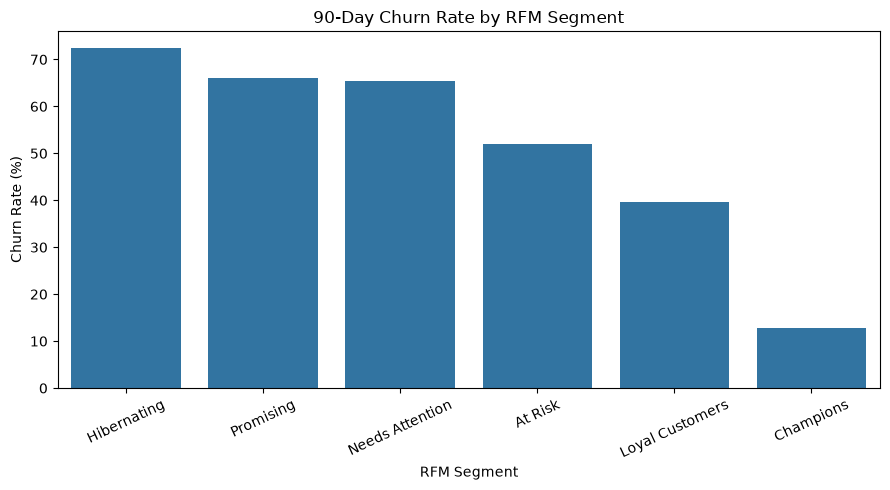

In [30]:
segment_plot = (
    segment_profile
    .reset_index()
    .sort_values("churn_rate", ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_plot,
    x="segment",
    y="churn_rate"
)

plt.title("90-Day Churn Rate by RFM Segment")
plt.xlabel("RFM Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()

plt.show()

### 3.5 K-Means Customer Segmentation

RFM segmentation uses predefined business rules, while K-Means is an unsupervised machine-learning algorithm that groups customers based on similarity in their purchasing behavior.

K-Means is sensitive to differences in feature scale and extreme values. Therefore, Frequency and Monetary Value are log-transformed to reduce their strong right skew, and all three RFM variables are standardized before clustering.

#### 3.5.1 Prepare Features for K-Means

In [31]:
kmeans_features = rfm[
    [
        "recency_days",
        "frequency",
        "monetary_value",
    ]
].copy()


# Reduce the strong skew in frequency and monetary value.
kmeans_features["frequency"] = np.log1p(
    kmeans_features["frequency"]
)

kmeans_features["monetary_value"] = np.log1p(
    kmeans_features["monetary_value"]
)


# Standardize features so that no variable dominates
# simply because it has a larger numerical scale.
scaler = StandardScaler()

kmeans_scaled = scaler.fit_transform(
    kmeans_features
)

print("K-Means feature matrix shape:", kmeans_scaled.shape)

print("\nScaled feature means:")
print(kmeans_scaled.mean(axis=0).round(4))

print("\nScaled feature standard deviations:")
print(kmeans_scaled.std(axis=0).round(4))

K-Means feature matrix shape: (2658, 3)

Scaled feature means:
[-0. -0.  0.]

Scaled feature standard deviations:
[1. 1. 1.]


#### 3.5.2 Select the Number of K-Means Clusters

Several values of `k` are compared using:

- **Inertia:** how tightly customers are grouped within clusters; lower is better, but it naturally decreases as more clusters are added.
- **Silhouette score:** how well separated the clusters are; higher values indicate clearer cluster structure.

The final choice should balance statistical separation with business interpretability.

In [32]:
from sklearn.metrics import silhouette_score


k_results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(kmeans_scaled)

    k_results.append(
        {
            "k": k,
            "inertia": model.inertia_,
            "silhouette_score": silhouette_score(
                kmeans_scaled,
                cluster_labels
            ),
        }
    )


k_evaluation = pd.DataFrame(k_results)

k_evaluation["inertia"] = (
    k_evaluation["inertia"].round(2)
)

k_evaluation["silhouette_score"] = (
    k_evaluation["silhouette_score"].round(3)
)

k_evaluation

,k,inertia,silhouette_score
0,2,4333.78,0.402
1,3,2967.76,0.360
2,4,2288.02,0.344
3,5,1971.19,0.337
4,6,1696.78,0.309


#### K-Means Cluster-Count Evaluation — Interpretation

Among the tested values, `k = 2` produced the highest silhouette score (0.402), indicating the clearest statistical separation.

However, two clusters may be too broad for useful customer segmentation. `k = 3` still provides reasonable separation (0.360) while allowing an additional behavioral group.

Therefore, the three-cluster solution is examined in more detail before selecting the final K-Means configuration.

#### 3.5.3 Profile a Three-Cluster K-Means Solution

In [33]:
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["kmeans_cluster"] = kmeans_3.fit_predict(
    kmeans_scaled
)


cluster_profile = (
    rfm
    .groupby("kmeans_cluster")
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary_value", "median"),
    )
    .round(2)
)

cluster_profile

,customers,median_recency,median_frequency,median_monetary
kmeans_cluster,,,,
0,795,122.0,1.0,251.93
1,640,16.0,5.0,1740.04
2,1223,36.0,1.0,409.57


#### Three-Cluster Behavioral Profile — Interpretation

The three-cluster solution produces distinct purchasing profiles.

- **Cluster 0** contains customers with the longest recency, low frequency, and relatively low spending.
- **Cluster 1** contains the most active and valuable customers, with recent purchases, substantially higher purchase frequency, and the highest median spending.
- **Cluster 2** contains relatively recent customers with lower purchase frequency and moderate spending.

The clusters are interpretable from historical behavior, but their subsequent churn rates are examined before assigning final business labels.

#### 3.5.4 Evaluate Future Churn by K-Means Cluster

In [34]:
kmeans_profile = rfm.merge(
    validation_snapshot[["customer_id", "churn"]],
    on="customer_id",
    how="left"
)

cluster_churn_profile = (
    kmeans_profile
    .groupby("kmeans_cluster")
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary_value", "median"),
        churn_rate=("churn", "mean"),
    )
)

cluster_churn_profile["median_monetary"] = (
    cluster_churn_profile["median_monetary"].round(2)
)

cluster_churn_profile["churn_rate"] = (
    cluster_churn_profile["churn_rate"] * 100
).round(2)

cluster_churn_profile

,customers,median_recency,median_frequency,median_monetary,churn_rate
kmeans_cluster,,,,,
0,795,122.0,1.0,251.93,70.06
1,640,16.0,5.0,1740.04,17.34
2,1223,36.0,1.0,409.57,54.13


#### K-Means Churn Profile — Interpretation

The three K-Means clusters also show substantial differences in subsequent churn behavior.

- **Cluster 0** has the highest churn rate at 70.06%. Its customers have the longest median recency, low purchase frequency, and relatively low spending.
- **Cluster 1** has the lowest churn rate at 17.34%. These customers are recent, frequent purchasers with the highest median monetary value.
- **Cluster 2** has an intermediate churn rate of 54.13%. Customers are more recent than Cluster 0 but typically have only one purchase during the observation window.

The unsupervised clusters therefore capture meaningful differences in customer retention without using the future churn label during clustering.

#### 3.5.5 Assign Business Labels to K-Means Clusters

In [35]:
cluster_names = {
    0: "Inactive Low-Value",
    1: "High-Value Active",
    2: "Recent Low-Frequency",
}

rfm["kmeans_segment"] = (
    rfm["kmeans_cluster"]
    .map(cluster_names)
)

rfm[
    [
        "customer_id",
        "recency_days",
        "frequency",
        "monetary_value",
        "segment",
        "kmeans_segment",
    ]
].head(10)

,customer_id,recency_days,frequency,monetary_value,segment,kmeans_segment
0,12346,134,1,77183.60,At Risk,High-Value Active
1,12347,55,3,1823.43,Loyal Customers,High-Value Active
2,12348,57,3,1167.24,Loyal Customers,High-Value Active
3,12350,119,1,294.40,Hibernating,Inactive Low-Value
4,12352,71,4,641.51,At Risk,High-Value Active
5,12353,13,1,89.00,Promising,Recent Low-Frequency
6,12354,41,1,1079.40,Needs Attention,Recent Low-Frequency
7,12355,23,1,459.40,Promising,Recent Low-Frequency
8,12356,54,2,2429.08,Loyal Customers,High-Value Active
9,12359,114,2,2386.41,At Risk,Inactive Low-Value


#### RFM vs. K-Means — Initial Comparison

The two segmentation approaches capture similar broad behavioral patterns but do not assign every customer identically.

K-Means groups customers according to overall numerical similarity across Recency, Frequency, and Monetary Value. As a result, an unusually high value on one dimension can influence cluster membership even when the customer's other behavior differs from the typical cluster profile.

RFM segmentation applies explicit business rules to each dimension separately, which can make cases such as high-value but inactive customers easier to identify and interpret.

#### 3.5.6 Compare RFM and K-Means Segment Assignments

In [36]:
segment_comparison = pd.crosstab(
    rfm["segment"],
    rfm["kmeans_segment"],
    margins=True
)

segment_comparison

kmeans_segment,High-Value Active,Inactive Low-Value,Recent Low-Frequency,All
segment,,,,
At Risk,42,178,124,344
Champions,468,0,28,496
Hibernating,0,613,100,713
Loyal Customers,129,0,465,594
Needs Attention,0,4,254,258
Promising,1,0,252,253
All,640,795,1223,2658


#### RFM vs. K-Means — Final Segmentation Decision

The two segmentation approaches show substantial agreement for the clearest behavioral groups.

- 468 of 496 RFM Champions are classified by K-Means as High-Value Active.
- 613 of 713 Hibernating customers are classified as Inactive Low-Value.
- Nearly all Promising and Needs Attention customers fall into the Recent Low-Frequency K-Means cluster.
- At Risk customers are distributed across all three K-Means clusters, showing that their behavior is more nuanced.

K-Means successfully identifies broad customer-behavior patterns without predefined rules, but its three clusters are relatively coarse.

RFM provides more granular and business-interpretable segments, particularly for identifying valuable customers whose recent activity has weakened. Therefore, RFM is retained as the primary customer-segmentation framework, while K-Means serves as an unsupervised comparison.

### 3.6 Churn Prediction

The next step is to predict whether an eligible customer will make no purchase during the 90 days following a cutoff date.

The prediction models use only behavioral information calculated during the preceding 180-day observation window.

Customer identifiers, cutoff dates, and future churn outcomes are excluded from the model inputs to prevent leakage.

#### 3.6.1 Prepare Modeling Features and Target

In [37]:
feature_columns = [
    "recency_days",
    "frequency",
    "monetary_value",
    "total_units",
    "avg_order_value",
]


X_train = train_snapshots[feature_columns].copy()
y_train = train_snapshots["churn"].copy()

X_validation = validation_snapshot[feature_columns].copy()
y_validation = validation_snapshot["churn"].copy()

X_test = test_snapshot[feature_columns].copy()
y_test = test_snapshot["churn"].copy()


# PostgreSQL numeric columns may arrive as Decimal objects.
# Convert all modeling features to regular numeric values.
for column in feature_columns:
    X_train[column] = pd.to_numeric(X_train[column])
    X_validation[column] = pd.to_numeric(X_validation[column])
    X_test[column] = pd.to_numeric(X_test[column])


print("Features:")
print(feature_columns)

print("\nTraining:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Final test:", X_test.shape, y_test.shape)

print("\nMissing values:")
print("Training:", X_train.isna().sum().sum())
print("Validation:", X_validation.isna().sum().sum())
print("Final test:", X_test.isna().sum().sum())

Features:
['recency_days', 'frequency', 'monetary_value', 'total_units', 'avg_order_value']

Training: (9625, 5) (9625,)
Validation: (2658, 5) (2658,)
Final test: (2768, 5) (2768,)

Missing values:
Training: 0
Validation: 0
Final test: 0


#### 3.6.2 Preprocess Features for Logistic Regression

Logistic Regression is sensitive to feature scale and extreme skew.

The strongly right-skewed purchasing variables are therefore transformed using `log1p`, which compresses very large values while preserving their ordering. The resulting features are then standardized using parameters learned from the training data only.

Fitting the preprocessing steps only on the training data prevents information from later periods from leaking into model development.

In [38]:
# Features with strong right skew.
log_features = [
    "frequency",
    "monetary_value",
    "total_units",
    "avg_order_value",
]


X_train_lr = X_train.copy()
X_validation_lr = X_validation.copy()
X_test_lr = X_test.copy()


# Apply the same log transformation to each split.
for column in log_features:
    X_train_lr[column] = np.log1p(X_train_lr[column])
    X_validation_lr[column] = np.log1p(X_validation_lr[column])
    X_test_lr[column] = np.log1p(X_test_lr[column])


# Fit scaling parameters using training data only.
lr_scaler = StandardScaler()

X_train_lr_scaled = lr_scaler.fit_transform(X_train_lr)
X_validation_lr_scaled = lr_scaler.transform(X_validation_lr)
X_test_lr_scaled = lr_scaler.transform(X_test_lr)


print("Training scaled means:")
print(X_train_lr_scaled.mean(axis=0).round(4))

print("\nTraining scaled standard deviations:")
print(X_train_lr_scaled.std(axis=0).round(4))

print("\nValidation shape:", X_validation_lr_scaled.shape)
print("Final test shape:", X_test_lr_scaled.shape)

Training scaled means:
[-0. -0.  0. -0.  0.]

Training scaled standard deviations:
[1. 1. 1. 1. 1.]

Validation shape: (2658, 5)
Final test shape: (2768, 5)


#### 3.6.3 Train the Logistic Regression Baseline

Logistic Regression provides a simple and interpretable baseline for churn prediction.

The model is trained on the three earliest historical snapshots and evaluated on the later 2011-06-01 validation snapshot. The final test period remains untouched.

In [39]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_lr_scaled,
    y_train
)


# Probability that each validation customer will churn.
validation_prob_lr = logistic_model.predict_proba(
    X_validation_lr_scaled
)[:, 1]


# Default classification threshold of 0.5.
validation_pred_lr = (
    validation_prob_lr >= 0.5
).astype(int)


validation_pr_auc_lr = average_precision_score(
    y_validation,
    validation_prob_lr
)


print(
    "Validation PR-AUC:",
    round(validation_pr_auc_lr, 3)
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        validation_pred_lr,
        digits=3
    )
)

Validation PR-AUC: 0.699

Classification report:
              precision    recall  f1-score   support

           0      0.769     0.508     0.611      1328
           1      0.633     0.847     0.725      1330

    accuracy                          0.678      2658
   macro avg      0.701     0.677     0.668      2658
weighted avg      0.701     0.678     0.668      2658



#### Logistic Regression Baseline — Validation Results

The Logistic Regression baseline achieved a validation PR-AUC of **0.699**, indicating meaningful separation between customers who subsequently churned and those who returned.

Using the default 0.50 probability threshold:

- churn recall was **84.7%**, meaning the model identified most customers who subsequently churned;
- churn precision was **63.3%**, meaning approximately two-thirds of customers predicted to churn actually did so;
- churn F1-score was **0.725**;
- overall accuracy was **67.8%**.

Because a retention team cannot necessarily contact every customer predicted to churn, model performance will also be evaluated under a fixed customer-contact budget.

#### 3.6.4 Evaluate Recall at a 20% Contact Budget

A retention team may have limited capacity and be able to contact only a fraction of customers.

The validation customers are therefore ranked by predicted churn probability, and the model is evaluated on how many actual churners are captured within the highest-risk 20% of customers.

In [40]:
contact_budget = 0.20

validation_ranking_lr = pd.DataFrame({
    "actual_churn": y_validation.to_numpy(),
    "predicted_probability": validation_prob_lr,
})

validation_ranking_lr = validation_ranking_lr.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

customers_to_contact = int(
    np.ceil(len(validation_ranking_lr) * contact_budget)
)

contacted_lr = validation_ranking_lr.head(customers_to_contact)

actual_churners = validation_ranking_lr["actual_churn"].sum()
captured_churners = contacted_lr["actual_churn"].sum()

recall_at_budget_lr = captured_churners / actual_churners
precision_at_budget_lr = contacted_lr["actual_churn"].mean()


print("Customers in validation set:", len(validation_ranking_lr))
print("20% contact budget:", customers_to_contact)

print("\nActual churners:", actual_churners)
print("Churners captured:", captured_churners)

print(
    "\nRecall at 20% budget:",
    f"{recall_at_budget_lr:.2%}"
)

print(
    "Precision at 20% budget:",
    f"{precision_at_budget_lr:.2%}"
)

Customers in validation set: 2658
20% contact budget: 532

Actual churners: 1330
Churners captured: 397

Recall at 20% budget: 29.85%
Precision at 20% budget: 74.62%


#### Logistic Regression — Contact-Budget Interpretation

Under a 20% customer-contact budget, Logistic Regression selects the 532 customers with the highest predicted churn probabilities.

Within this group:

- **397 actual churners** are captured;
- **recall at the 20% budget is 29.85%**, meaning roughly 30% of all future churners are contained within the highest-risk fifth of customers;
- **precision at the 20% budget is 74.62%**, meaning nearly three-quarters of contacted customers subsequently churned.

This demonstrates that the model provides useful ranking information even when the business cannot contact every customer predicted to be at risk.

#### 3.6.5 Prepare XGBoost Model

In [43]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ModuleNotFoundError:
    print("XGBoost is not installed.")

XGBoost version: 3.2.0


#### 3.6.6 Train an XGBoost Churn Model

XGBoost is a gradient-boosted tree model capable of learning nonlinear relationships and interactions between customer-behavior features.

The model is trained on the same historical training snapshots and evaluated on the same time-based validation period as Logistic Regression, allowing a fair comparison.

In [44]:
from xgboost import XGBClassifier


xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)


xgb_model.fit(
    X_train,
    y_train
)


validation_prob_xgb = xgb_model.predict_proba(
    X_validation
)[:, 1]

validation_pred_xgb = (
    validation_prob_xgb >= 0.5
).astype(int)


validation_pr_auc_xgb = average_precision_score(
    y_validation,
    validation_prob_xgb
)


print(
    "Validation PR-AUC:",
    round(validation_pr_auc_xgb, 3)
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        validation_pred_xgb,
        digits=3
    )
)

Validation PR-AUC: 0.684

Classification report:
              precision    recall  f1-score   support

           0      0.771     0.518     0.620      1328
           1      0.638     0.847     0.727      1330

    accuracy                          0.682      2658
   macro avg      0.704     0.682     0.674      2658
weighted avg      0.704     0.682     0.674      2658



#### XGBoost Validation Results — Interpretation

The XGBoost model achieved a validation PR-AUC of **0.684**, compared with **0.699** for Logistic Regression.

At the default 0.50 threshold:

- churn recall was **84.7%**;
- churn precision was **63.8%**;
- churn F1-score was **0.727**;
- overall accuracy was **68.2%**.

Although XGBoost achieved slightly higher classification accuracy and F1-score, its PR-AUC was lower than the Logistic Regression baseline.

This suggests that the additional nonlinear complexity of XGBoost does not currently improve churn-risk ranking for this feature set.

#### 3.6.7 Evaluate XGBoost at a 20% Contact Budget

In [45]:
validation_ranking_xgb = pd.DataFrame({
    "actual_churn": y_validation.to_numpy(),
    "predicted_probability": validation_prob_xgb,
})

validation_ranking_xgb = validation_ranking_xgb.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

contacted_xgb = validation_ranking_xgb.head(
    customers_to_contact
)

captured_churners_xgb = contacted_xgb["actual_churn"].sum()

recall_at_budget_xgb = (
    captured_churners_xgb / actual_churners
)

precision_at_budget_xgb = (
    contacted_xgb["actual_churn"].mean()
)


print("Customers contacted:", customers_to_contact)
print("Actual churners:", actual_churners)
print("Churners captured:", captured_churners_xgb)

print(
    "\nRecall at 20% budget:",
    f"{recall_at_budget_xgb:.2%}"
)

print(
    "Precision at 20% budget:",
    f"{precision_at_budget_xgb:.2%}"
)

Customers contacted: 532
Actual churners: 1330
Churners captured: 379

Recall at 20% budget: 28.50%
Precision at 20% budget: 71.24%


#### Logistic Regression vs. XGBoost — Model Selection

Logistic Regression outperformed XGBoost on the validation metrics most relevant to the retention use case.

At a 20% customer-contact budget:

- Logistic Regression captured **397 churners**, with **29.85% recall** and **74.62% precision**.
- XGBoost captured **379 churners**, with **28.50% recall** and **71.24% precision**.

Logistic Regression also achieved the higher PR-AUC:

- **Logistic Regression:** 0.699
- **XGBoost:** 0.684

Although XGBoost produced slightly higher overall accuracy and F1-score at the default 0.50 threshold, Logistic Regression performed better at ranking the customers most relevant for a constrained retention campaign.

Therefore, **Logistic Regression is selected as the final churn model** for this phase.

#### 3.6.8 Validation Model Comparison

In [46]:
model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "XGBoost",
    ],
    "PR_AUC": [
        validation_pr_auc_lr,
        validation_pr_auc_xgb,
    ],
    "recall_at_20pct_budget": [
        recall_at_budget_lr,
        recall_at_budget_xgb,
    ],
    "precision_at_20pct_budget": [
        precision_at_budget_lr,
        precision_at_budget_xgb,
    ],
})

model_comparison[
    [
        "PR_AUC",
        "recall_at_20pct_budget",
        "precision_at_20pct_budget",
    ]
] = model_comparison[
    [
        "PR_AUC",
        "recall_at_20pct_budget",
        "precision_at_20pct_budget",
    ]
].round(3)

model_comparison

,model,PR_AUC,recall_at_20pct_budget,precision_at_20pct_budget
0,Logistic Regression,0.699,0.298,0.746
1,XGBoost,0.684,0.285,0.712


#### 3.6.9 Refit the Selected Model on All Development Data

After selecting Logistic Regression using the validation period, the training and validation snapshots are combined.

The preprocessing scaler and Logistic Regression model are then refitted using all four development snapshots. The final 2011-09-01 snapshot remains excluded and will be used only once for final evaluation.

In [47]:
# Combine the original training snapshots with the validation snapshot.
development_snapshot = pd.concat(
    [
        train_snapshots,
        validation_snapshot,
    ],
    ignore_index=True
)

X_development = development_snapshot[feature_columns].copy()
y_development = development_snapshot["churn"].copy()


# Convert database numeric types to regular numeric values.
for column in feature_columns:
    X_development[column] = pd.to_numeric(
        X_development[column]
    )


# Apply the same log transformations used during model selection.
X_development_lr = X_development.copy()

for column in log_features:
    X_development_lr[column] = np.log1p(
        X_development_lr[column]
    )


# Refit preprocessing using all development data.
final_scaler = StandardScaler()

X_development_scaled = final_scaler.fit_transform(
    X_development_lr
)


# Refit the selected model.
final_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

final_logistic_model.fit(
    X_development_scaled,
    y_development
)


print("Development rows:", len(X_development))
print(
    "Development churn rate:",
    f"{y_development.mean():.2%}"
)

print("\nFinal Logistic Regression model refitted successfully.")

Development rows: 12283
Development churn rate: 52.70%

Final Logistic Regression model refitted successfully.


#### 3.6.10 Final Evaluation on the Untouched Test Period

The final Logistic Regression model is evaluated once on the 2011-09-01 snapshot.

This period was not used for model selection, preprocessing decisions, or parameter fitting, so it provides the most realistic estimate of how the model generalizes to a later time period.

In [48]:
# Prepare the untouched final-test features
# using the exact same transformations as development data.
X_test_final = X_test.copy()

for column in log_features:
    X_test_final[column] = np.log1p(
        X_test_final[column]
    )


# Apply the scaler fitted only on development data.
X_test_final_scaled = final_scaler.transform(
    X_test_final
)


# Predict churn probability.
test_prob_lr = final_logistic_model.predict_proba(
    X_test_final_scaled
)[:, 1]


# Default 0.50 threshold.
test_pred_lr = (
    test_prob_lr >= 0.5
).astype(int)


test_pr_auc = average_precision_score(
    y_test,
    test_prob_lr
)


print(
    "Final test PR-AUC:",
    round(test_pr_auc, 3)
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_pred_lr,
        digits=3
    )
)

Final test PR-AUC: 0.588

Classification report:
              precision    recall  f1-score   support

           0      0.827     0.506     0.628      1680
           1      0.523     0.836     0.644      1088

    accuracy                          0.636      2768
   macro avg      0.675     0.671     0.636      2768
weighted avg      0.707     0.636     0.634      2768



#### Final Test Performance — Interpretation

The final Logistic Regression model achieved a PR-AUC of **0.588** on the untouched 2011-09-01 test period.

The validation PR-AUC was **0.699**, while the final-test PR-AUC was **0.588**. However, these values should not be interpreted as direct evidence of a deterioration in model discrimination because the positive-class prevalence changed substantially between the two periods.

The validation churn rate was **50.04%**, whereas the final-test churn rate was **39.31%**. Because PR-AUC is affected by positive-class prevalence, a lower PR-AUC is partly expected when the churn base rate decreases.

The final-test PR-AUC remains above the approximately **0.393** no-skill baseline implied by the test-period churn prevalence, indicating that the model still provides useful churn-risk ranking.

At the default 0.50 threshold:

- churn recall was **83.6%**;
- churn precision was **52.3%**;
- churn F1-score was **0.644**;
- overall accuracy was **63.6%**.

Additional prevalence-insensitive discrimination metrics and contact-budget evaluations are examined below before drawing conclusions about temporal generalization.

#### 3.6.11 ROC-AUC Across Validation and Final Test Periods

PR-AUC depends on the prevalence of the positive class, so it should be interpreted carefully when churn rates differ substantially across time periods.

ROC-AUC is less sensitive to class prevalence and provides an additional measure of how well the model ranks churned customers above non-churned customers.

In [50]:
from sklearn.metrics import roc_auc_score


validation_roc_auc_lr = roc_auc_score(
    y_validation,
    validation_prob_lr
)

test_roc_auc_lr = roc_auc_score(
    y_test,
    test_prob_lr
)


print(
    "Validation ROC-AUC:",
    round(validation_roc_auc_lr, 3)
)

print(
    "Final test ROC-AUC:",
    round(test_roc_auc_lr, 3)
)

Validation ROC-AUC: 0.75
Final test ROC-AUC: 0.732


#### ROC-AUC Interpretation

The Logistic Regression model achieved:

- **Validation ROC-AUC:** 0.750
- **Final test ROC-AUC:** 0.732

Unlike PR-AUC, ROC-AUC is much less sensitive to changes in the churn base rate. The relatively small decline from 0.750 to 0.732 suggests that the model's ability to rank churned customers above non-churned customers remained fairly stable across the later test period.

This indicates that the larger decline in PR-AUC from 0.699 to 0.588 should not be interpreted entirely as model deterioration, because the final-test churn prevalence was substantially lower than the validation churn prevalence.

#### 3.6.12 Final Test Performance at a 20% Contact Budget

In [49]:
test_ranking = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "predicted_probability": test_prob_lr,
})

test_ranking = test_ranking.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)


test_customers_to_contact = int(
    np.ceil(len(test_ranking) * 0.20)
)

test_contacted = test_ranking.head(
    test_customers_to_contact
)

test_actual_churners = test_ranking["actual_churn"].sum()
test_captured_churners = test_contacted["actual_churn"].sum()

test_recall_at_budget = (
    test_captured_churners / test_actual_churners
)

test_precision_at_budget = (
    test_contacted["actual_churn"].mean()
)


print("Customers in final test set:", len(test_ranking))
print("20% contact budget:", test_customers_to_contact)

print("\nActual churners:", test_actual_churners)
print("Churners captured:", test_captured_churners)

print(
    "\nRecall at 20% budget:",
    f"{test_recall_at_budget:.2%}"
)

print(
    "Precision at 20% budget:",
    f"{test_precision_at_budget:.2%}"
)

Customers in final test set: 2768
20% contact budget: 554

Actual churners: 1088
Churners captured: 351

Recall at 20% budget: 32.26%
Precision at 20% budget: 63.36%


#### Final Test Contact-Budget Interpretation

Under a 20% contact budget, the final Logistic Regression model targets the 554 customers with the highest predicted churn risk.

Within this targeted group:

- **351 of the 1,088 actual churners** are captured;
- **recall at the 20% budget is 32.26%**;
- **precision at the 20% budget is 63.36%**.

The overall test-period churn rate is 39.31%, while 63.36% of the targeted customers churned. This corresponds to approximately a **1.61× lift in churn concentration** relative to untargeted selection.

This result shows that the model still provides useful prioritization under a constrained retention budget. However, comparisons between validation and test periods should account for their different churn base rates rather than interpreting the difference in PR-AUC alone as evidence of worse model discrimination.

#### 3.6.13 Contact-Budget Sensitivity Analysis

A retention team may have different campaign capacities, so model performance is evaluated at several contact-budget levels rather than at 20% alone.

The top 5%, 10%, and 20% of customers are selected according to predicted churn probability.

For each budget, the analysis reports:

- **Recall:** percentage of all actual churners captured by the targeted group;
- **Precision:** percentage of targeted customers who actually churned;
- **Lift:** how much more concentrated churn is within the targeted group compared with the overall churn rate.

These results describe the behavior of the already-selected Logistic Regression model and are not used for further model selection.

In [51]:
def evaluate_contact_budgets(
    y_true,
    probabilities,
    budgets,
    period_name
):
    """Evaluate churn targeting at several customer-contact budgets."""

    ranking = pd.DataFrame({
        "actual_churn": np.asarray(y_true),
        "predicted_probability": probabilities,
    }).sort_values(
        "predicted_probability",
        ascending=False
    ).reset_index(drop=True)

    total_churners = ranking["actual_churn"].sum()
    overall_churn_rate = ranking["actual_churn"].mean()

    results = []

    for budget in budgets:
        customers_to_contact = int(
            np.ceil(len(ranking) * budget)
        )

        contacted = ranking.head(customers_to_contact)

        captured_churners = contacted["actual_churn"].sum()
        recall = captured_churners / total_churners
        precision = contacted["actual_churn"].mean()
        lift = precision / overall_churn_rate

        results.append({
            "period": period_name,
            "contact_budget": f"{int(budget * 100)}%",
            "customers_contacted": customers_to_contact,
            "churners_captured": int(captured_churners),
            "recall_pct": recall * 100,
            "precision_pct": precision * 100,
            "lift": lift,
        })

    return pd.DataFrame(results)


budgets = [0.05, 0.10, 0.20]


validation_budget_results = evaluate_contact_budgets(
    y_validation,
    validation_prob_lr,
    budgets,
    "Validation"
)

test_budget_results = evaluate_contact_budgets(
    y_test,
    test_prob_lr,
    budgets,
    "Final Test"
)


budget_comparison = pd.concat(
    [
        validation_budget_results,
        test_budget_results,
    ],
    ignore_index=True
)


budget_comparison[
    ["recall_pct", "precision_pct", "lift"]
] = budget_comparison[
    ["recall_pct", "precision_pct", "lift"]
].round(2)


budget_comparison

,period,contact_budget,customers_contacted,churners_captured,recall_pct,precision_pct,lift
0,Validation,5%,133,95,7.14,71.43,1.43
1,Validation,10%,266,202,15.19,75.94,1.52
2,Validation,20%,532,397,29.85,74.62,1.49
3,Final Test,5%,139,95,8.73,68.35,1.74
4,Final Test,10%,277,183,16.82,66.06,1.68
5,Final Test,20%,554,351,32.26,63.36,1.61


#### Contact-Budget Sensitivity — Interpretation

The model provides useful churn-risk concentration across several campaign sizes.

On the final test period:

- targeting the highest-risk **5%** of customers captures **8.73%** of all churners, with **68.35% precision** and **1.74× lift**;
- targeting the highest-risk **10%** captures **16.82%** of churners, with **66.06% precision** and **1.68× lift**;
- targeting the highest-risk **20%** captures **32.26%** of churners, with **63.36% precision** and **1.61× lift**.

As the contact budget increases, recall increases because more customers can be reached, while precision and lift generally decrease because progressively lower-risk customers are included.

The same general pattern appears in validation. This demonstrates that the churn model can support different retention-campaign capacities rather than depending on a single arbitrary contact threshold.

#### 3.6.14 Cumulative Lift Curve

A cumulative lift curve shows how much more concentrated actual churners are within the highest-risk customers ranked by the model compared with random targeting.

A lift of:

- **1.0×** means the targeted group contains churners at the same rate as the overall population;
- **greater than 1.0×** means the model is concentrating churners more effectively than random selection.

The curve is shown for both the validation and final-test periods to assess whether the ranking behavior remains useful over time.

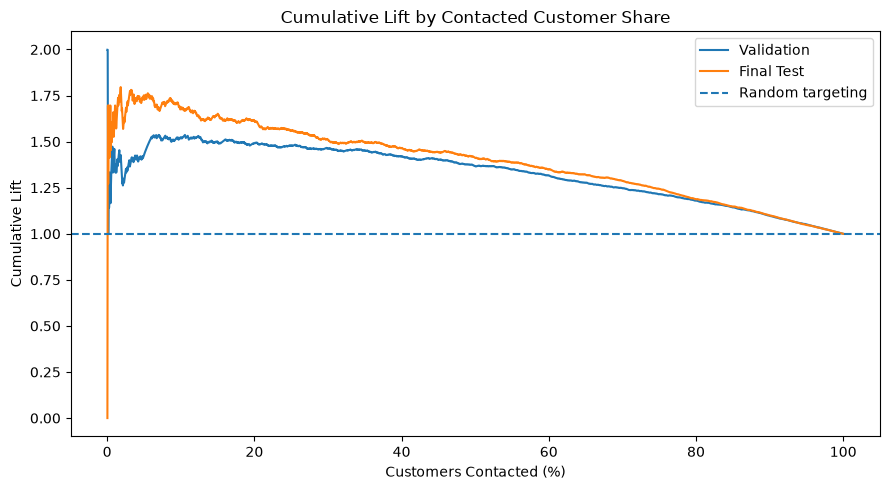

In [52]:
def cumulative_lift_curve(y_true, probabilities):
    """Calculate cumulative lift after ranking customers by churn risk."""

    ranking = pd.DataFrame({
        "actual_churn": np.asarray(y_true),
        "predicted_probability": probabilities,
    }).sort_values(
        "predicted_probability",
        ascending=False
    ).reset_index(drop=True)

    overall_churn_rate = ranking["actual_churn"].mean()

    ranking["customers_contacted_pct"] = (
        (np.arange(1, len(ranking) + 1) / len(ranking)) * 100
    )

    ranking["cumulative_precision"] = (
        ranking["actual_churn"].cumsum()
        / np.arange(1, len(ranking) + 1)
    )

    ranking["cumulative_lift"] = (
        ranking["cumulative_precision"]
        / overall_churn_rate
    )

    return ranking


validation_lift = cumulative_lift_curve(
    y_validation,
    validation_prob_lr
)

test_lift = cumulative_lift_curve(
    y_test,
    test_prob_lr
)


plt.figure(figsize=(9, 5))

plt.plot(
    validation_lift["customers_contacted_pct"],
    validation_lift["cumulative_lift"],
    label="Validation"
)

plt.plot(
    test_lift["customers_contacted_pct"],
    test_lift["cumulative_lift"],
    label="Final Test"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Random targeting"
)

plt.title("Cumulative Lift by Contacted Customer Share")
plt.xlabel("Customers Contacted (%)")
plt.ylabel("Cumulative Lift")
plt.legend()
plt.tight_layout()

plt.show()

#### Cumulative Lift Curve — Interpretation

Both the validation and final-test lift curves remain above the random-targeting baseline for most of the customer ranking, showing that the model consistently concentrates churners toward the highest predicted-risk customers.

The strongest lift occurs at smaller contact budgets. In the final test period, lift is approximately:

- **1.74×** at a 5% contact budget;
- **1.68×** at a 10% contact budget;
- **1.61×** at a 20% contact budget.

Lift gradually approaches 1.0 as a larger share of customers is included, which is expected because targeting eventually approaches the full population.

The instability at the extreme left edge of the curve reflects the very small number of customers included in the first few cumulative observations and should not be over-interpreted.

### 3.7 Phase 3 Enhancement — Richer Behavioral Features

The original churn model used five RFM-style purchasing features. To test whether richer customer behavior improves prediction and provides more informative explanations in the next phase, an enhanced feature set is constructed.

The additional features describe customer engagement, product breadth, purchasing history within the observation window, and whether activity is concentrated near the cutoff.

Because the final 2011-09-01 test result has already been inspected, the enhanced feature set and model choice are evaluated using the historical development and validation periods only. The final test period will not be used to choose the enhanced model.

#### 3.7.1 Build an Enhanced Leakage-Safe Snapshot

In [54]:
def build_enhanced_customer_snapshot(cutoff_date, engine):
    """
    Build a leakage-safe customer snapshot with richer behavioral features.

    Features use only the 180 days before the cutoff.
    Churn uses only the following 90 days.
    """

    cutoff_date = pd.Timestamp(cutoff_date)
    observation_start = cutoff_date - pd.Timedelta(days=180)
    recent_start = cutoff_date - pd.Timedelta(days=30)
    label_end = cutoff_date + pd.Timedelta(days=90)

    query = """
    WITH observation AS (
        SELECT
            customer_id,
            MAX(invoice_date) AS last_purchase_date,
            MIN(invoice_date) AS first_purchase_date,
            COUNT(DISTINCT invoice) AS frequency,
            SUM(line_revenue) AS monetary_value,
            SUM(quantity) AS total_units,
            SUM(line_revenue) / COUNT(DISTINCT invoice) AS avg_order_value,

            -- Additional behavioral features.
            COUNT(DISTINCT invoice_date::date) AS active_days,
            COUNT(DISTINCT stock_code) AS product_diversity,

            COUNT(
                DISTINCT CASE
                    WHEN invoice_date >= :recent_start
                    THEN invoice
                END
            ) AS orders_last_30d,

            SUM(
                CASE
                    WHEN invoice_date >= :recent_start
                    THEN line_revenue
                    ELSE 0
                END
            ) AS revenue_last_30d

        FROM retail_transactions
        WHERE invoice_date >= :observation_start
          AND invoice_date < :cutoff_date
        GROUP BY customer_id
    ),

    future_purchases AS (
        SELECT DISTINCT customer_id
        FROM retail_transactions
        WHERE invoice_date >= :cutoff_date
          AND invoice_date < :label_end
    )

    SELECT
        o.customer_id,
        CAST(:cutoff_date AS timestamp) AS cutoff_date,

        CAST(:cutoff_date AS date)
            - CAST(o.last_purchase_date AS date) AS recency_days,

        o.frequency,
        ROUND(o.monetary_value, 2) AS monetary_value,
        o.total_units,
        ROUND(o.avg_order_value, 2) AS avg_order_value,

        o.active_days,
        o.product_diversity,

        CAST(o.last_purchase_date AS date)
            - CAST(o.first_purchase_date AS date)
            AS purchase_span_days,

        ROUND(
            o.orders_last_30d::numeric
            / NULLIF(o.frequency, 0),
            4
        ) AS recent_30d_order_share,

        ROUND(
            o.revenue_last_30d
            / NULLIF(o.monetary_value, 0),
            4
        ) AS recent_30d_revenue_share,

        CASE
            WHEN f.customer_id IS NULL THEN 1
            ELSE 0
        END AS churn

    FROM observation o

    LEFT JOIN future_purchases f
        ON o.customer_id = f.customer_id

    ORDER BY o.customer_id;
    """

    params = {
        "observation_start": observation_start,
        "recent_start": recent_start,
        "cutoff_date": cutoff_date,
        "label_end": label_end,
    }

    with engine.connect() as connection:
        snapshot = pd.read_sql(
            text(query),
            connection,
            params=params
        )

    return snapshot

#### 3.7.2 Generate Enhanced Development Snapshots

In [55]:
enhanced_cutoffs = [
    "2010-09-01",
    "2010-12-01",
    "2011-03-01",
    "2011-06-01",
]

enhanced_snapshots = {}

for cutoff in enhanced_cutoffs:
    enhanced_snapshots[cutoff] = build_enhanced_customer_snapshot(
        cutoff,
        engine
    )


enhanced_summary = pd.DataFrame(
    [
        {
            "cutoff_date": cutoff,
            "customers": len(snapshot),
            "churn_rate": snapshot["churn"].mean(),
        }
        for cutoff, snapshot in enhanced_snapshots.items()
    ]
)

enhanced_summary["churn_rate"] = (
    enhanced_summary["churn_rate"] * 100
).round(2)

enhanced_summary

,cutoff_date,customers,churn_rate
0,2010-09-01,2822,37.99
1,2010-12-01,3465,61.96
2,2011-03-01,3338,57.64
3,2011-06-01,2658,50.04


#### 3.7.3 Prepare the Enhanced Modeling Dataset

The first three enhanced snapshots are used for training and the 2011-06-01 snapshot remains the validation period.

The enhanced model contains the original five behavioral variables plus five additional leakage-safe features. The final 2011-09-01 test period is not used during this model-development step.

In [56]:
enhanced_feature_columns = [
    # Original features.
    "recency_days",
    "frequency",
    "monetary_value",
    "total_units",
    "avg_order_value",

    # New behavioral features.
    "active_days",
    "product_diversity",
    "purchase_span_days",
    "recent_30d_order_share",
    "recent_30d_revenue_share",
]


enhanced_train = pd.concat(
    [
        enhanced_snapshots["2010-09-01"],
        enhanced_snapshots["2010-12-01"],
        enhanced_snapshots["2011-03-01"],
    ],
    ignore_index=True
)

enhanced_validation = (
    enhanced_snapshots["2011-06-01"].copy()
)


X_train_enhanced = enhanced_train[
    enhanced_feature_columns
].copy()

y_train_enhanced = enhanced_train["churn"].copy()

X_validation_enhanced = enhanced_validation[
    enhanced_feature_columns
].copy()

y_validation_enhanced = enhanced_validation["churn"].copy()


# Convert PostgreSQL numeric types to standard numeric values.
for column in enhanced_feature_columns:
    X_train_enhanced[column] = pd.to_numeric(
        X_train_enhanced[column]
    )

    X_validation_enhanced[column] = pd.to_numeric(
        X_validation_enhanced[column]
    )


print("Enhanced features:")
print(enhanced_feature_columns)

print("\nTraining:", X_train_enhanced.shape)
print("Validation:", X_validation_enhanced.shape)

print("\nMissing values:")
print("Training:", X_train_enhanced.isna().sum().sum())
print(
    "Validation:",
    X_validation_enhanced.isna().sum().sum()
)

print("\nRecent-share ranges:")
print(
    X_train_enhanced[
        [
            "recent_30d_order_share",
            "recent_30d_revenue_share",
        ]
    ].agg(["min", "max"])
)

Enhanced features:
['recency_days', 'frequency', 'monetary_value', 'total_units', 'avg_order_value', 'active_days', 'product_diversity', 'purchase_span_days', 'recent_30d_order_share', 'recent_30d_revenue_share']

Training: (9625, 10)
Validation: (2658, 10)

Missing values:
Training: 0
Validation: 0

Recent-share ranges:
     recent_30d_order_share  recent_30d_revenue_share
min                     0.0                       0.0
max                     1.0                       1.0


#### 3.7.4 Preprocess Enhanced Features for Logistic Regression

The enhanced feature set contains several highly skewed count and monetary variables. These variables are log-transformed before standardization.

Recency and the two recent-activity share features are left on their original scales before standardization because they are already bounded or directly interpretable.

As before, all preprocessing parameters are learned from the training snapshots only.

In [57]:
enhanced_log_features = [
    "frequency",
    "monetary_value",
    "total_units",
    "avg_order_value",
    "active_days",
    "product_diversity",
    "purchase_span_days",
]


X_train_enhanced_lr = X_train_enhanced.copy()
X_validation_enhanced_lr = X_validation_enhanced.copy()


for column in enhanced_log_features:
    X_train_enhanced_lr[column] = np.log1p(
        X_train_enhanced_lr[column]
    )

    X_validation_enhanced_lr[column] = np.log1p(
        X_validation_enhanced_lr[column]
    )


enhanced_scaler = StandardScaler()

X_train_enhanced_scaled = enhanced_scaler.fit_transform(
    X_train_enhanced_lr
)

X_validation_enhanced_scaled = enhanced_scaler.transform(
    X_validation_enhanced_lr
)


print("Training scaled means:")
print(
    X_train_enhanced_scaled.mean(axis=0).round(4)
)

print("\nTraining scaled standard deviations:")
print(
    X_train_enhanced_scaled.std(axis=0).round(4)
)

print(
    "\nValidation shape:",
    X_validation_enhanced_scaled.shape
)

Training scaled means:
[-0. -0.  0. -0.  0. -0.  0.  0. -0.  0.]

Training scaled standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Validation shape: (2658, 10)


#### 3.7.5 Train the Enhanced Logistic Regression Model

The original Logistic Regression baseline used five RFM-style behavioral features. The enhanced model uses the same algorithm and training periods but adds five richer behavioral variables.

Using the same validation period allows the effect of feature engineering to be assessed without changing the model family or evaluation design.

In [58]:
enhanced_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

enhanced_logistic_model.fit(
    X_train_enhanced_scaled,
    y_train_enhanced
)


validation_prob_enhanced_lr = (
    enhanced_logistic_model.predict_proba(
        X_validation_enhanced_scaled
    )[:, 1]
)


validation_pr_auc_enhanced_lr = average_precision_score(
    y_validation_enhanced,
    validation_prob_enhanced_lr
)

validation_roc_auc_enhanced_lr = roc_auc_score(
    y_validation_enhanced,
    validation_prob_enhanced_lr
)


print(
    "Enhanced Logistic Regression PR-AUC:",
    round(validation_pr_auc_enhanced_lr, 3)
)

print(
    "Enhanced Logistic Regression ROC-AUC:",
    round(validation_roc_auc_enhanced_lr, 3)
)

print("\nOriginal 5-feature Logistic Regression:")
print(
    "PR-AUC:",
    round(validation_pr_auc_lr, 3)
)
print(
    "ROC-AUC:",
    round(validation_roc_auc_lr, 3)
)

Enhanced Logistic Regression PR-AUC: 0.697
Enhanced Logistic Regression ROC-AUC: 0.751

Original 5-feature Logistic Regression:
PR-AUC: 0.699
ROC-AUC: 0.75


#### Enhanced Logistic Regression — Interpretation

Adding the five richer behavioral features did not materially improve Logistic Regression on the validation period.

- **Original PR-AUC:** 0.699
- **Enhanced PR-AUC:** 0.697
- **Original ROC-AUC:** 0.750
- **Enhanced ROC-AUC:** 0.751

The differences are negligible, suggesting that the additional variables provide little extra linear predictive signal beyond the original five behavioral features.

However, some of the new variables may interact with existing features in nonlinear ways. The enhanced feature set is therefore also evaluated with XGBoost before deciding whether it adds useful predictive value.

#### 3.7.6 Train Enhanced XGBoost

In [59]:
enhanced_xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)


enhanced_xgb_model.fit(
    X_train_enhanced,
    y_train_enhanced
)


validation_prob_enhanced_xgb = (
    enhanced_xgb_model.predict_proba(
        X_validation_enhanced
    )[:, 1]
)


validation_pr_auc_enhanced_xgb = average_precision_score(
    y_validation_enhanced,
    validation_prob_enhanced_xgb
)

validation_roc_auc_enhanced_xgb = roc_auc_score(
    y_validation_enhanced,
    validation_prob_enhanced_xgb
)


print(
    "Enhanced XGBoost PR-AUC:",
    round(validation_pr_auc_enhanced_xgb, 3)
)

print(
    "Enhanced XGBoost ROC-AUC:",
    round(validation_roc_auc_enhanced_xgb, 3)
)

print("\nOriginal 5-feature XGBoost:")
print(
    "PR-AUC:",
    round(validation_pr_auc_xgb, 3)
)

print(
    "ROC-AUC:",
    round(
        roc_auc_score(
            y_validation,
            validation_prob_xgb
        ),
        3
    )
)

Enhanced XGBoost PR-AUC: 0.684
Enhanced XGBoost ROC-AUC: 0.741

Original 5-feature XGBoost:
PR-AUC: 0.684
ROC-AUC: 0.741


#### 3.7.7 Compare Enhanced Models at Contact Budgets

Although the richer feature set did not improve PR-AUC or ROC-AUC, it may still change the ordering of the highest-risk customers.

The original and enhanced models are therefore compared at 5%, 10%, and 20% validation contact budgets before the final model specification is chosen.

In [60]:
validation_budget_original_lr = evaluate_contact_budgets(
    y_validation,
    validation_prob_lr,
    budgets,
    "Original Logistic Regression"
)

validation_budget_enhanced_lr = evaluate_contact_budgets(
    y_validation_enhanced,
    validation_prob_enhanced_lr,
    budgets,
    "Enhanced Logistic Regression"
)

validation_budget_original_xgb = evaluate_contact_budgets(
    y_validation,
    validation_prob_xgb,
    budgets,
    "Original XGBoost"
)

validation_budget_enhanced_xgb = evaluate_contact_budgets(
    y_validation_enhanced,
    validation_prob_enhanced_xgb,
    budgets,
    "Enhanced XGBoost"
)


enhanced_budget_comparison = pd.concat(
    [
        validation_budget_original_lr,
        validation_budget_enhanced_lr,
        validation_budget_original_xgb,
        validation_budget_enhanced_xgb,
    ],
    ignore_index=True
)


enhanced_budget_comparison[
    ["recall_pct", "precision_pct", "lift"]
] = enhanced_budget_comparison[
    ["recall_pct", "precision_pct", "lift"]
].round(2)


enhanced_budget_comparison[
    [
        "period",
        "contact_budget",
        "recall_pct",
        "precision_pct",
        "lift",
    ]
]

,period,contact_budget,recall_pct,precision_pct,lift
0,Original Logistic Regression,5%,7.14,71.43,1.43
1,Original Logistic Regression,10%,15.19,75.94,1.52
2,Original Logistic Regression,20%,29.85,74.62,1.49
3,Enhanced Logistic Regression,5%,7.14,71.43,1.43
4,Enhanced Logistic Regression,10%,15.26,76.32,1.53
5,Enhanced Logistic Regression,20%,29.55,73.87,1.48
6,Original XGBoost,5%,6.99,69.92,1.40
7,Original XGBoost,10%,14.14,70.68,1.41
8,Original XGBoost,20%,28.50,71.24,1.42
9,Enhanced XGBoost,5%,7.07,70.68,1.41


#### Enhanced Feature Experiment — Final Decision

The richer behavioral feature set did not provide a meaningful validation improvement.

For Logistic Regression:

- PR-AUC changed from **0.699 to 0.697**;
- ROC-AUC changed from **0.750 to 0.751**;
- contact-budget performance remained effectively unchanged.

At the 10% contact budget, the enhanced Logistic Regression produced only a marginal improvement, while the original model performed slightly better at the 20% budget.

For XGBoost, both PR-AUC and ROC-AUC were unchanged to three decimal places, and contact-budget performance also showed no meaningful improvement.

Given the lack of consistent predictive gain, the **original five-feature Logistic Regression is retained as the final churn model**. It provides comparable or better performance with fewer variables and greater interpretability.

The enhanced models are not evaluated on the final test period because the validation results do not justify changing the previously selected model specification. This avoids unnecessary post-hoc use of the already-inspected test set.

### 3.8 Phase 3 Limitations

The Phase 3 results should be interpreted with several limitations in mind.

- **Churn is an operational definition rather than permanent customer loss.** A customer is labeled as churned when they make no qualifying merchandise purchase during the 90 days after a cutoff. They may still return at a later date.

- **Customer behavior is summarized using a fixed 180-day observation window.** Purchasing activity outside that window is intentionally excluded from the predictive features.

- **The modeling table contains positive qualifying merchandise purchases only.** Returns, cancellations, administrative transactions, and other excluded transaction types are not represented in the current churn features.

- **The same customer can appear in multiple historical snapshots.** Each row represents the customer at a different point in time. Temporal train, validation, and test periods are kept separate to preserve chronological evaluation, but snapshot observations are not fully independent.

- **PR-AUC changes with churn prevalence.** Validation and final-test churn rates differ substantially, so PR-AUC values should not be compared without considering the base rate. ROC-AUC and contact-budget lift are reported as complementary measures.

- **The final test period was inspected after the original five-feature model was selected.** Subsequent feature-engineering experiments were therefore evaluated using validation data only and were not used to search for a better-performing test result.

- **The model estimates association, not causation.** A high predicted churn probability does not prove that a specific customer behavior causes churn or that contacting the customer will prevent it.

- **Probability calibration has not yet been evaluated.** Phase 3 focuses primarily on ranking and classification performance. Calibration will be assessed before predicted probabilities are used for expected revenue-at-risk calculations in Phase 4.

### 3.9 Phase 3 Summary

Phase 3 combined interpretable customer segmentation with leakage-safe churn prediction and time-based model evaluation.

#### Customer Segmentation

Two segmentation approaches were compared:

- **RFM segmentation** produced six business-oriented customer groups.
- **K-Means clustering** produced three broader behavioral groups.

The RFM segments showed clear differences in subsequent 90-day churn behavior:

- **Champions:** 12.90% churn
- **Loyal Customers:** 39.56%
- **At Risk:** 52.03%
- **Needs Attention:** 65.50%
- **Promising:** 66.01%
- **Hibernating:** 72.37%

RFM was retained as the primary segmentation framework because it provided more granular and business-interpretable customer groups, particularly for identifying valuable customers whose recent activity had weakened.

#### Churn Modeling

Customer features were calculated using only the 180 days preceding each cutoff date. Churn was defined as making no qualifying merchandise purchase during the following 90 days.

The chronological model-development design used:

- 2010-09-01, 2010-12-01, and 2011-03-01 snapshots for training;
- 2011-06-01 for validation;
- 2011-09-01 as the original untouched final test period.

Using the original five behavioral features, two models were compared on validation:

- **Logistic Regression:** PR-AUC = 0.699
- **XGBoost:** PR-AUC = 0.684

At a 20% validation contact budget, Logistic Regression also performed better:

- recall = **29.85%**
- precision = **74.62%**

Logistic Regression was therefore selected as the final churn model.

#### Final Test Evaluation

After refitting Logistic Regression on all development periods, the original final-test evaluation produced:

- **PR-AUC:** 0.588
- **ROC-AUC:** 0.732
- **churn recall at a 0.50 threshold:** 83.6%
- **churn precision at a 0.50 threshold:** 52.3%

The validation ROC-AUC was 0.750, compared with 0.732 on the final test period. This relatively small difference indicates that ranking discrimination remained broadly similar across the later period.

The larger change in PR-AUC from 0.699 to 0.588 should not be interpreted independently of the change in churn prevalence: validation churn was 50.04%, while final-test churn was 39.31%.

#### Contact-Budget Performance

On the final test period:

- targeting the top **5%** of predicted-risk customers captured **8.73%** of all churners with **68.35% precision** and **1.74× lift**;
- targeting the top **10%** captured **16.82%** of churners with **66.06% precision** and **1.68× lift**;
- targeting the top **20%** captured **32.26%** of churners with **63.36% precision** and **1.61× lift**.

The cumulative lift curve remained above random targeting across most of the ranking, showing that the model provides useful prioritization under different campaign capacities.

#### Enhanced Feature Experiment

Five additional leakage-safe behavioral features were evaluated:

- active purchasing days;
- product diversity;
- purchase span;
- recent 30-day order share;
- recent 30-day revenue share.

These features did not materially improve validation performance.

For Logistic Regression:

- PR-AUC changed from **0.699 to 0.697**;
- ROC-AUC changed from **0.750 to 0.751**;
- contact-budget performance remained effectively unchanged.

For XGBoost:

- PR-AUC remained **0.684**;
- ROC-AUC remained **0.741**.

Because the richer feature set provided no consistent predictive improvement, the original **five-feature Logistic Regression** was retained as the final Phase 3 model.

The enhanced models were not evaluated on the final test period because that period had already been inspected and validation results did not justify changing the selected model specification.

Overall, Phase 3 produced an interpretable retention-risk workflow that combines business segmentation, chronological validation, churn ranking, and campaign-oriented targeting metrics while maintaining explicit leakage controls.